# <font color = "red">**Deciphering the Decision Logic of an AI Agent**</font>

- Can we infer what an AI agent values by observing the sequence of decisions it makes?

- In this challenge, GPT acts as an autonomous microscopy agent that repeatedly selects one measurement location from a set of candidate AFM image patches.

- We record its decisions and then attempt to reverse-engineer the hidden logic behind those choices using visual, statistical, and data-driven methods.

<font color = "blue" size = 6>**Goal**</font>: develop a method that best explains GPT’s behavior and predicts its future decisions on unseen candidate sets.

<a href="https://colab.research.google.com/github/kbarakati/camm_hackathon/blob/k4my4r/docs/day_23_10232026/llm_decision_making_spectrum.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Imports and reproducibility

In [ ]:
! pip install -q igor2

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from igor2 import binarywave
import pickle

# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------

import random
np.random.seed(42)
import glob
import pickle


Download data

In [ ]:
! gdown --folder "https://drive.google.com/drive/folders/1qN-AdhA19oHG3yNo7te7stjzQ_VM1OY_?usp=sharing"

## load data

In [ ]:
fname = "/content/Plasmonic_sets_hackathon.npy"

raw = np.load(fname, allow_pickle=True)
loadedfile = raw.tolist()

print("Available datasets:", loadedfile.keys())

Available datasets: dict_keys(['0', '1', '2', '3'])


In [ ]:
# Use the same dataset as the previous challenge
data = loadedfile["0"]

image = data["image"]
spectra = data["spectrum image"]
energy = data["energy axis"]

H, W, N_E = spectra.shape

print("Image:", image.shape)
print("Spectral image:", spectra.shape)
print("Energy axis:", energy.shape)

Image: (66, 152)
Spectral image: (66, 152, 4198)
Energy axis: (4198,)


## <font color="purple">**2.**</font> Explore the Spectra

Before clustering, always look at the data.

The structural image tells us **where** each spectrum was measured.  
The spectra tell us **what the local EELS response looks like**.

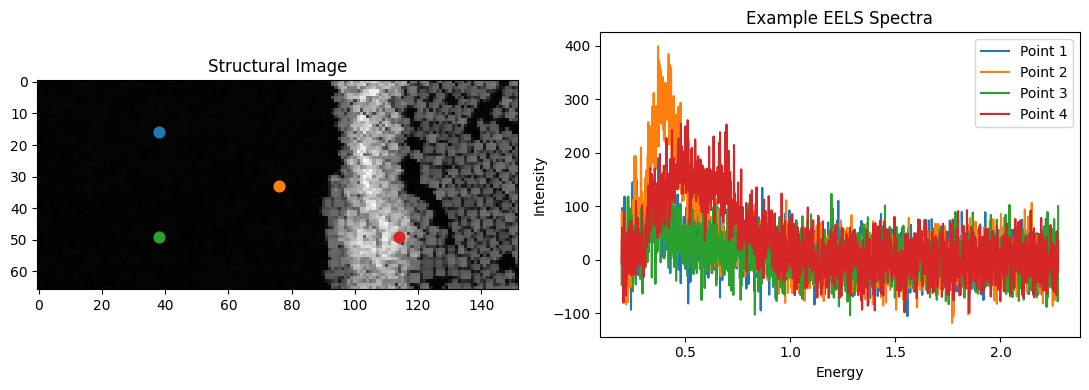

In [ ]:
# Pick a few example locations
positions = [
    (H // 4, W // 4),
    (H // 2, W // 2),
    (3 * H // 4, W // 4),
    (3 * H // 4, 3 * W // 4),
]

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].imshow(image, cmap="gray")
ax[0].set_title("Structural Image")

for i, (y, x) in enumerate(positions):
    ax[0].scatter(x, y, s=60)
    ax[1].plot(energy, spectra[y, x], label=f"Point {i + 1}")

ax[1].set_title("Example EELS Spectra")
ax[1].set_xlabel("Energy")
ax[1].set_ylabel("Intensity")
ax[1].legend()

plt.tight_layout()
plt.show()

Traces

In [ ]:
trace_files = [
    "/content/day_22/eels_ei_trace.pkl",
    "/content/day_22/eels_random_trace.pkl",
    "/content/day_22/eels_ucb_trace.pkl",
    "/content/day_22/trace_P01_eels_.pkl",
    "/content/day_22/trace_P03_eels.pkl"
]

traces = {}

for i, fname in enumerate(trace_files):
    with open(fname, "rb") as f:
        traces[i] = pickle.load(f)

    print(f"Trace {i}: {fname.split('/')[-1]}")

Trace 0: eels_ei_trace.pkl
Trace 1: eels_random_trace.pkl
Trace 2: eels_ucb_trace.pkl
Trace 3: trace_P01_eels_.pkl
Trace 4: trace_P03_eels.pkl


Understanding the EELS Decision Traces
Each trace contains a sequence of decisions made by an agent while exploring an EELS dataset.

At each decision step, the agent is presented with several possible measurement locations and selects one.

For every step, the recorded information may include:
- candidate_positions — spatial coordinates of all available measurement locations.
- selected_position — index of the candidate selected by the agent.
- selected_spectrum — EELS spectrum measured at the selected location.
- selected_axis — corresponding energy-loss axis (eV).
- step — decision step number.
The four traces represent different decision-making strategies: Expected Improvement (EI), Random Sampling, Upper Confidence Bound (UCB), and PO6.

In [ ]:
TRACE_ID = 4
STEP = 1

trace = traces[TRACE_ID]
step_data = trace["decisions"][STEP - 1]

print("Step:", step_data["step"])

print("Selected candidate position:", step_data["selected_position"])
print("Selected dataset index:", step_data["selected_index"])
print("Selected coordinates:", step_data["selected_coordinates"])

print("Number of candidates:", len(step_data["candidate_indices"]))
print("Candidate indices:", step_data["candidate_indices"])
print("Candidate coordinates:", step_data["candidate_coordinates"])

# print("Selected reward:", step_data["selected_reward"])

print("Selected spectrum shape:", np.shape(step_data["selected_spectrum"]))
print("Energy axis shape:", np.shape(step_data["selected_axis"]))

Step: 1
Selected candidate position: 10
Selected dataset index: 3926
Selected coordinates: [ 25 126]
Number of candidates: 20
Candidate indices: [ 844 7959 7939 3644 6871 2156 2717 5571 6716 9399 3926 6660 3532  642
 3058 1992 1662 7401 3327 5374]
Candidate coordinates: [[  5  84]
 [ 52  55]
 [ 52  35]
 [ 23 148]
 [ 45  31]
 [ 14  28]
 [ 17 133]
 [ 36  99]
 [ 44  28]
 [ 61 127]
 [ 25 126]
 [ 43 124]
 [ 23  36]
 [  4  34]
 [ 20  18]
 [ 13  16]
 [ 10 142]
 [ 48 105]
 [ 21 135]
 [ 35  54]]
Selected spectrum shape: (4198,)
Energy axis shape: (4198,)


VISUALIZE ONE DECISION STEP

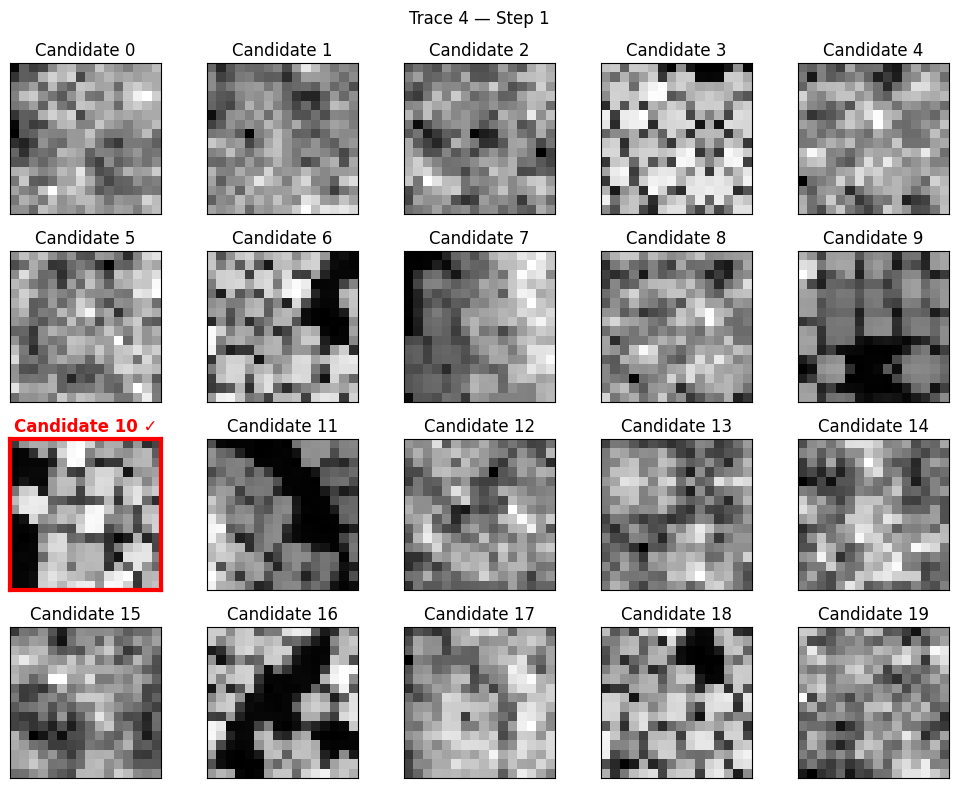

In [ ]:
patches = step_data["candidate_patches"]
selected = step_data["selected_position"]

n = len(patches)

ncols = 5
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(10, 2 * nrows)
)

axes = np.array(axes).reshape(-1)

for i, ax in enumerate(axes):

    if i >= n:
        ax.axis("off")
        continue

    patch = np.squeeze(patches[i])   # <-- fixes (1,16,16) -> (16,16)

    ax.imshow(
        patch,
        cmap="gray"
    )

    if i == selected:

        ax.set_title(
            f"Candidate {i} ✓",
            color="red",
            weight="bold"
        )

        for spine in ax.spines.values():
            spine.set_edgecolor("red")
            spine.set_linewidth(3)

    else:

        ax.set_title(
            f"Candidate {i}"
        )

    ax.set_xticks([])
    ax.set_yticks([])

plt.suptitle(
    f"Trace {TRACE_ID} — Step {STEP}"
)

plt.tight_layout()
plt.show()

Show the spectrum

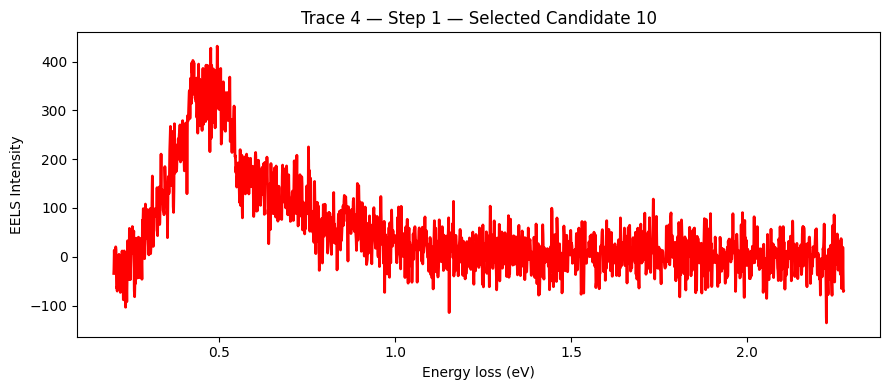

In [ ]:
energy = step_data["selected_axis"]
spectrum = step_data["selected_spectrum"]

plt.figure(figsize=(9, 4))

plt.plot(energy, spectrum, color="red", linewidth=2)

plt.xlabel("Energy loss (eV)")
plt.ylabel("EELS Intensity")
plt.title(f"Trace {TRACE_ID} — Step {STEP} — Selected Candidate {selected}")

plt.tight_layout()
plt.show()

TRACE MAP ON ORIGINAL IMAGE

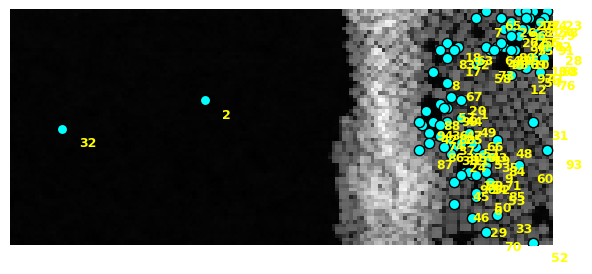

In [ ]:
trace = traces[TRACE_ID]
decisions = trace["decisions"]

xs = [d["selected_coordinates"][1] for d in decisions]
ys = [d["selected_coordinates"][0] for d in decisions]

fig, ax = plt.subplots(figsize=(7, 7))

ax.imshow(image, cmap="gray")

ax.scatter(
    xs, ys,
    s=55,
    color="cyan",
    edgecolors="black"
)

for i, (x, y) in enumerate(zip(xs, ys)):
    ax.text(
        x + 5,
        y + 5,
        str(decisions[i]["step"]),
        fontsize=9,
        color="yellow",
        weight="bold"
    )

ax.axis("off")
plt.show()

DECISION MAPS FOR 10 TRACES


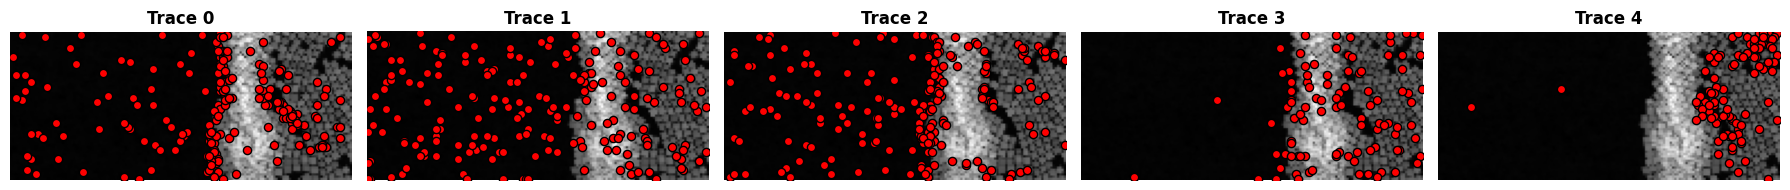

In [ ]:
TRACE_IDS = list(traces.keys())

ncols = 5
nrows = int(np.ceil(len(TRACE_IDS) / ncols))

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(18, 5 * nrows)
)

axes = np.array(axes).flatten()

for ax, trace_id in zip(axes, TRACE_IDS):

    trace = traces[trace_id]
    decisions = trace["decisions"]

    xs = [d["selected_coordinates"][1] for d in decisions]
    ys = [d["selected_coordinates"][0] for d in decisions]

    # Original EELS image
    ax.imshow(image, cmap="gray")

    # Selected locations
    ax.scatter(
        xs,
        ys,
        s=35,
        color="red",
        edgecolors="black"
    )

    ax.set_title(
        f"Trace {trace_id}",
        fontsize=12,
        weight="bold"
    )

    ax.axis("off")

# Hide unused axes
for ax in axes[len(TRACE_IDS):]:
    ax.axis("off")

plt.tight_layout()
plt.show()